# Lab 1 Solution: Approximate Computing on LeNet-5 (MNIST)
**Objective:** Apply approximation techniques (pruning, data compression) on a LeNet-5 CNN and measure their impact on performance.

In [6]:
import numpy as np
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torch.nn.utils.prune as prune
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score, accuracy_score
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

In [8]:
# Device setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

# Hyperparameters
BATCH_SIZE = 64
BASELINE_EPOCHS = 10
RETRAIN_EPOCHS = 5
RETRAIN_SCRATCH_EPOCHS = 10
LR = 0.001
FINETUNE_LR = 0.0005

torch.manual_seed(42)
np.random.seed(42)

Using device: cpu


In [9]:
# Load MNIST
train_ds = datasets.MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())
test_ds = datasets.MNIST(root='./data', train=False, download=True, transform=transforms.ToTensor())

x_train = train_ds.data.numpy().astype('float32') / 255.0
y_train = train_ds.targets.numpy()
x_test = test_ds.data.numpy().astype('float32') / 255.0
y_test = test_ds.targets.numpy()

# Add channel dim: (N,28,28) -> (N,1,28,28)
x_train = x_train[:, np.newaxis, :, :]
x_test = x_test[:, np.newaxis, :, :]

print(f'Training set: {x_train.shape}, Test set: {x_test.shape}')

Training set: (60000, 1, 28, 28), Test set: (10000, 1, 28, 28)


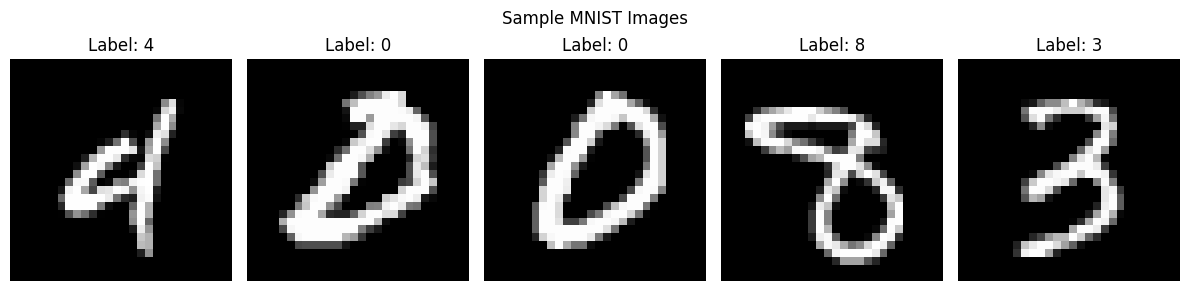

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i, ax in enumerate(axes):
    idx = np.random.randint(len(x_train))
    ax.imshow(x_train[idx, 0], cmap='gray')
    ax.set_title(f'Label: {y_train[idx]}')
    ax.axis('off')
plt.suptitle('Sample MNIST Images')
plt.tight_layout()
plt.show()

## LeNet-5 Architecture
- Conv1 (1→6, k=5, pad=2) → ReLU → MaxPool(2×2)
- Conv2 (6→16, k=5) → ReLU → MaxPool(2×2)
- FC1 (400→120) → ReLU
- FC2 (120→100) → ReLU
- FC3 (100→10) → Softmax (output)

In [11]:
class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5, padding=2)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 100)
        self.fc3 = nn.Linear(100, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 16 * 5 * 5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)  # raw logits; CrossEntropyLoss applies softmax
        return x

In [12]:
def make_loaders(xt, yt, xv, yv, bs=BATCH_SIZE):
    tr = DataLoader(TensorDataset(torch.FloatTensor(xt), torch.LongTensor(yt)),
                    batch_size=bs, shuffle=True)
    te = DataLoader(TensorDataset(torch.FloatTensor(xv), torch.LongTensor(yv)),
                    batch_size=bs, shuffle=False)
    return tr, te

def train_model(model, loader, epochs, lr=LR):
    model.train()
    opt = optim.Adam(model.parameters(), lr=lr)
    crit = nn.CrossEntropyLoss()
    for ep in range(1, epochs + 1):
        total_loss = 0
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(model(X), y)
            loss.backward()
            opt.step()
            total_loss += loss.item()
        if ep % max(1, epochs // 5) == 0 or ep == epochs:
            print(f'  Epoch {ep}/{epochs}  Loss: {total_loss/len(loader):.4f}')

def evaluate(model, loader):
    model.eval()
    preds, tgts = [], []
    with torch.no_grad():
        for X, y in loader:
            X = X.to(device)
            preds.extend(model(X).argmax(1).cpu().numpy())
            tgts.extend(y.numpy())
    f1 = f1_score(tgts, preds, average='weighted')
    acc = accuracy_score(tgts, preds)
    return f1, acc

## Baseline Model (No Approximation)

In [13]:
train_loader, test_loader = make_loaders(x_train, y_train, x_test, y_test)

baseline_model = LeNet5().to(device)
print('Training baseline LeNet-5...')
train_model(baseline_model, train_loader, BASELINE_EPOCHS)

train_f1, train_acc = evaluate(baseline_model, train_loader)
test_f1, test_acc = evaluate(baseline_model, test_loader)
print(f'\nBaseline Results:')
print(f'  Train — F1: {train_f1:.4f}, Acc: {train_acc:.4f}')
print(f'  Test  — F1: {test_f1:.4f}, Acc: {test_acc:.4f}')

# Save baseline state for later reuse
baseline_state = copy.deepcopy(baseline_model.state_dict())

Training baseline LeNet-5...
  Epoch 2/10  Loss: 0.0803
  Epoch 4/10  Loss: 0.0443
  Epoch 6/10  Loss: 0.0302
  Epoch 8/10  Loss: 0.0226
  Epoch 10/10  Loss: 0.0172

Baseline Results:
  Train — F1: 0.9971, Acc: 0.9971
  Test  — F1: 0.9917, Acc: 0.9917


## Task 1 — Weight Pruning on All Fully Connected Layers

Two pruning strategies applied to fc1, fc2, fc3:
1. **Random pruning** — uniformly remove weights at random
2. **Magnitude-based pruning** — remove weights with smallest |w|

Pruning levels: 10%, 20%, 30%, 40%, 50%.  
F1 score is measured **before** and **after** retraining (fine-tuning for 5 epochs).

In [14]:
def apply_pruning(model, amount, method='magnitude'):
    """Apply pruning to all Linear layers."""
    for module in [model.fc1, model.fc2, model.fc3]:
        if method == 'magnitude':
            prune.l1_unstructured(module, name='weight', amount=amount)
        else:
            prune.random_unstructured(module, name='weight', amount=amount)
    return model

def count_pruned(model):
    """Return (pruned, total) weight count for Linear layers."""
    pruned = total = 0
    for module in [model.fc1, model.fc2, model.fc3]:
        if hasattr(module, 'weight_mask'):
            mask = module.weight_mask
            pruned += int((mask == 0).sum())
            total += mask.numel()
        else:
            total += module.weight.numel()
    return pruned, total

In [15]:
prune_levels = [0.1, 0.2, 0.3, 0.4, 0.5]
results_task1 = []

for pct in prune_levels:
    for method in ['magnitude', 'random']:
        # Fresh copy of baseline
        model = LeNet5().to(device)
        model.load_state_dict(copy.deepcopy(baseline_state))

        # Apply pruning
        apply_pruning(model, pct, method)
        p, t = count_pruned(model)
        print(f'\n--- {method.upper()} pruning {int(pct*100)}%  (pruned {p}/{t}) ---')

        # Evaluate BEFORE retraining
        f1_train_before, _ = evaluate(model, train_loader)
        f1_test_before, _ = evaluate(model, test_loader)
        print(f'  Before retrain — Train F1: {f1_train_before:.4f}, Test F1: {f1_test_before:.4f}')

        # Retrain (fine-tune)
        train_model(model, train_loader, RETRAIN_EPOCHS, lr=FINETUNE_LR)

        # Evaluate AFTER retraining
        f1_train_after, _ = evaluate(model, train_loader)
        f1_test_after, _ = evaluate(model, test_loader)
        print(f'  After retrain  — Train F1: {f1_train_after:.4f}, Test F1: {f1_test_after:.4f}')

        results_task1.append({
            'Method': method.capitalize(),
            'Pruning %': int(pct * 100),
            'Train F1 (before)': round(f1_train_before, 4),
            'Test F1 (before)': round(f1_test_before, 4),
            'Train F1 (after)': round(f1_train_after, 4),
            'Test F1 (after)': round(f1_test_after, 4),
        })

print('\nDone with Task 1.')


--- MAGNITUDE pruning 10%  (pruned 6100/61000) ---
  Before retrain — Train F1: 0.9971, Test F1: 0.9915
  Epoch 1/5  Loss: 0.0088
  Epoch 2/5  Loss: 0.0052
  Epoch 3/5  Loss: 0.0053
  Epoch 4/5  Loss: 0.0044
  Epoch 5/5  Loss: 0.0038
  After retrain  — Train F1: 0.9991, Test F1: 0.9918

--- RANDOM pruning 10%  (pruned 6100/61000) ---
  Before retrain — Train F1: 0.9950, Test F1: 0.9899
  Epoch 1/5  Loss: 0.0108
  Epoch 2/5  Loss: 0.0070
  Epoch 3/5  Loss: 0.0054
  Epoch 4/5  Loss: 0.0053
  Epoch 5/5  Loss: 0.0053
  After retrain  — Train F1: 0.9985, Test F1: 0.9904

--- MAGNITUDE pruning 20%  (pruned 12200/61000) ---
  Before retrain — Train F1: 0.9970, Test F1: 0.9914
  Epoch 1/5  Loss: 0.0081
  Epoch 2/5  Loss: 0.0061
  Epoch 3/5  Loss: 0.0044
  Epoch 4/5  Loss: 0.0038
  Epoch 5/5  Loss: 0.0045
  After retrain  — Train F1: 0.9992, Test F1: 0.9908

--- RANDOM pruning 20%  (pruned 12200/61000) ---
  Before retrain — Train F1: 0.9926, Test F1: 0.9885
  Epoch 1/5  Loss: 0.0131
  Epoch 2

In [16]:
df1 = pd.DataFrame(results_task1)
print('\n=== Task 1: Weight Pruning Results ===')
print(f'Baseline — Train F1: {train_f1:.4f}, Test F1: {test_f1:.4f}\n')
display(df1)


=== Task 1: Weight Pruning Results ===
Baseline — Train F1: 0.9971, Test F1: 0.9917



,Method,Pruning %,Train F1 (before),Test F1 (before),Train F1 (after),Test F1 (after)
0,Magnitude,10,0.9971,0.9915,0.9991,0.9918
1,Random,10,0.9950,0.9899,0.9985,0.9904
2,Magnitude,20,0.9970,0.9914,0.9992,0.9908
3,Random,20,0.9926,0.9885,0.9987,0.9904
4,Magnitude,30,0.9968,0.9912,0.9989,0.9916
5,Random,30,0.9743,0.9682,0.9989,0.9918
6,Magnitude,40,0.9967,0.9913,0.9994,0.9916
7,Random,40,0.9719,0.9706,0.9978,0.9902
8,Magnitude,50,0.9955,0.9896,0.9985,0.9907
9,Random,50,0.9113,0.9040,0.9976,0.9914


### Task 1 — Analysis

**Observations:**
- **Magnitude-based pruning** generally preserves accuracy better than random pruning at the same level, because it removes the least impactful weights first.
-

## Task 2 — PCA Data Compression

Flatten MNIST images (28×28 → 784), apply PCA to remove 20% and 40% of the least important components, reconstruct images, and retrain the CNN.


--- PCA: removing 20% components ---
  PCA: kept 627/784 components, variance explained: 100.0%


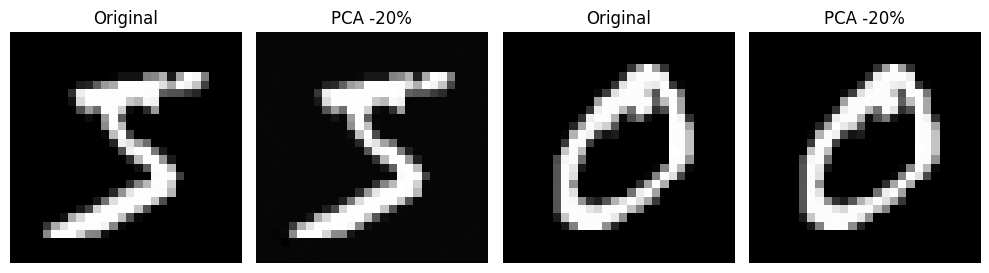

  Epoch 2/10  Loss: 0.0817
  Epoch 4/10  Loss: 0.0446
  Epoch 6/10  Loss: 0.0309
  Epoch 8/10  Loss: 0.0210
  Epoch 10/10  Loss: 0.0157
  Train F1: 0.9957, Test F1: 0.9887

--- PCA: removing 40% components ---
  PCA: kept 470/784 components, variance explained: 99.9%


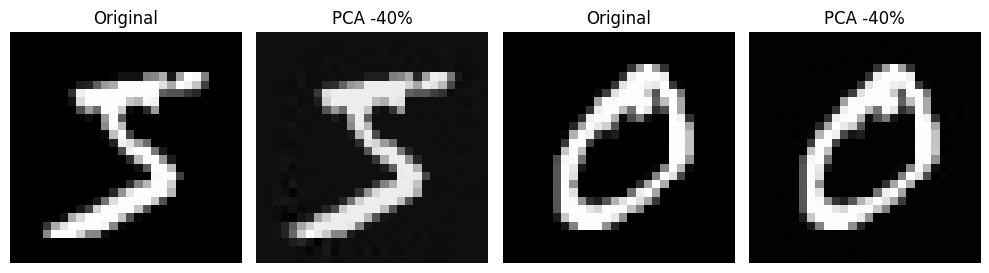

  Epoch 2/10  Loss: 0.0785
  Epoch 4/10  Loss: 0.0434
  Epoch 6/10  Loss: 0.0298
  Epoch 8/10  Loss: 0.0218
  Epoch 10/10  Loss: 0.0154
  Train F1: 0.9931, Test F1: 0.9856

Done with Task 2.


In [17]:
def pca_compress(x_tr, x_te, keep_ratio):
    """Apply PCA, keep `keep_ratio` fraction of components, reconstruct."""
    n_components = int(784 * keep_ratio)
    flat_tr = x_tr.reshape(len(x_tr), -1)
    flat_te = x_te.reshape(len(x_te), -1)
    pca = PCA(n_components=n_components)
    rec_tr = pca.inverse_transform(pca.fit_transform(flat_tr))
    rec_te = pca.inverse_transform(pca.transform(flat_te))
    var_explained = sum(pca.explained_variance_ratio_) * 100
    print(f'  PCA: kept {n_components}/784 components, variance explained: {var_explained:.1f}%')
    return rec_tr.reshape(-1, 1, 28, 28).astype('float32'), \
           rec_te.reshape(-1, 1, 28, 28).astype('float32')

results_task2 = []
for remove_pct in [0.2, 0.4]:
    keep = 1.0 - remove_pct
    print(f'\n--- PCA: removing {int(remove_pct*100)}% components ---')
    xtr_pca, xte_pca = pca_compress(x_train, x_test, keep)

    # Visualize
    fig, axes = plt.subplots(1, 4, figsize=(10, 3))
    idx = 0
    axes[0].imshow(x_train[idx, 0], cmap='gray'); axes[0].set_title('Original')
    axes[1].imshow(xtr_pca[idx, 0], cmap='gray'); axes[1].set_title(f'PCA -{int(remove_pct*100)}%')
    idx = 1
    axes[2].imshow(x_train[idx, 0], cmap='gray'); axes[2].set_title('Original')
    axes[3].imshow(xtr_pca[idx, 0], cmap='gray'); axes[3].set_title(f'PCA -{int(remove_pct*100)}%')
    for ax in axes: ax.axis('off')
    plt.tight_layout(); plt.show()

    # Train from scratch on compressed data
    tr_ld, te_ld = make_loaders(xtr_pca, y_train, xte_pca, y_test)
    model_pca = LeNet5().to(device)
    train_model(model_pca, tr_ld, RETRAIN_SCRATCH_EPOCHS)
    f1_tr, _ = evaluate(model_pca, tr_ld)
    f1_te, _ = evaluate(model_pca, te_ld)
    print(f'  Train F1: {f1_tr:.4f}, Test F1: {f1_te:.4f}')
    results_task2.append({
        'Removed %': int(remove_pct * 100),
        'Train F1': round(f1_tr, 4),
        'Test F1': round(f1_te, 4),
    })

print('\nDone with Task 2.')

In [ ]:
df2 = pd.DataFrame(results_task2)
print('\n=== Task 2: PCA Data Compression Results ===')
print(f'Baseline — Train F1: {train_f1:.4f}, Test F1: {test_f1:.4f}\n')
display(df2)

### Task 2 — Analysis

**Observations:**
- 

## Task 3 — Remove Non-Important Input Pixels (Low Variance)

Compute per-pixel variance across the training set. Zero out the 20% and 40% of pixels with the lowest variance. Retrain and evaluate.

In [ ]:
def remove_low_var_pixels(x_tr, x_te, remove_pct):
    """Zero out the `remove_pct` fraction of pixels with lowest variance."""
    flat_tr = x_tr.reshape(len(x_tr), -1)
    flat_te = x_te.reshape(len(x_te), -1)
    var = np.var(flat_tr, axis=0)
    n_remove = int(len(var) * remove_pct)
    low_var_idx = np.argsort(var)[:n_remove]
    out_tr = flat_tr.copy()
    out_te = flat_te.copy()
    out_tr[:, low_var_idx] = 0
    out_te[:, low_var_idx] = 0
    print(f'  Zeroed {n_remove}/784 pixels')
    return out_tr.reshape(-1, 1, 28, 28), out_te.reshape(-1, 1, 28, 28), low_var_idx

results_task3 = []
for remove_pct in [0.2, 0.4]:
    print(f'\n--- Removing {int(remove_pct*100)}% lowest-variance pixels ---')
    xtr_var, xte_var, removed_idx = remove_low_var_pixels(x_train, x_test, remove_pct)

    # Visualize removed pixels mask
    mask = np.ones(784)
    mask[removed_idx] = 0
    fig, axes = plt.subplots(1, 3, figsize=(9, 3))
    axes[0].imshow(mask.reshape(28, 28), cmap='gray'); axes[0].set_title('Pixel mask (white=kept)')
    axes[1].imshow(x_train[0, 0], cmap='gray'); axes[1].set_title('Original')
    axes[2].imshow(xtr_var[0, 0], cmap='gray'); axes[2].set_title(f'After removal')
    for ax in axes: ax.axis('off')
    plt.tight_layout(); plt.show()

    tr_ld, te_ld = make_loaders(xtr_var, y_train, xte_var, y_test)
    model_var = LeNet5().to(device)
    train_model(model_var, tr_ld, RETRAIN_SCRATCH_EPOCHS)
    f1_tr, _ = evaluate(model_var, tr_ld)
    f1_te, _ = evaluate(model_var, te_ld)
    print(f'  Train F1: {f1_tr:.4f}, Test F1: {f1_te:.4f}')
    results_task3.append({
        'Removed %': int(remove_pct * 100),
        'Train F1': round(f1_tr, 4),
        'Test F1': round(f1_te, 4),
    })

print('\nDone with Task 3.')

In [ ]:
df3 = pd.DataFrame(results_task3)
print('\n=== Task 3: Low-Variance Pixel Removal Results ===')
print(f'Baseline — Train F1: {train_f1:.4f}, Test F1: {test_f1:.4f}\n')
display(df3)

### Task 3 — Analysis

**Observations:**
-

## Task 4 — Combined: PCA Compression + Weight Pruning

We combine **Task 2 (PCA)** with **Task 1 (Weight Pruning)**:
1. Apply PCA compression (remove 20% components)
2. Train the model on compressed data
3. Apply magnitude-based weight pruning at various levels
4. Fine-tune and evaluate

In [ ]:
# Step 1: PCA compress (remove 20%)
print('Step 1: Applying PCA compression (remove 20% components)...')
xtr_pca, xte_pca = pca_compress(x_train, x_test, keep_ratio=0.8)
tr_ld_pca, te_ld_pca = make_loaders(xtr_pca, y_train, xte_pca, y_test)

# Step 2: Train model on compressed data
print('\nStep 2: Training model on PCA-compressed data...')
model_combined_base = LeNet5().to(device)
train_model(model_combined_base, tr_ld_pca, RETRAIN_SCRATCH_EPOCHS)
f1_tr_base, _ = evaluate(model_combined_base, tr_ld_pca)
f1_te_base, _ = evaluate(model_combined_base, te_ld_pca)
print(f'  PCA-only — Train F1: {f1_tr_base:.4f}, Test F1: {f1_te_base:.4f}')
combined_state = copy.deepcopy(model_combined_base.state_dict())

# Step 3 & 4: Apply pruning + retrain
results_task4 = []
results_task4.append({
    'Config': 'PCA-20% only (no pruning)',
    'Pruning %': 0,
    'Train F1 (before retrain)': round(f1_tr_base, 4),
    'Test F1 (before retrain)': round(f1_te_base, 4),
    'Train F1 (after retrain)': round(f1_tr_base, 4),
    'Test F1 (after retrain)': round(f1_te_base, 4),
})

for pct in [0.1, 0.2, 0.3, 0.5]:
    print(f'\n--- PCA-20% + Magnitude pruning {int(pct*100)}% ---')
    m = LeNet5().to(device)
    m.load_state_dict(copy.deepcopy(combined_state))
    apply_pruning(m, pct, 'magnitude')

    f1_tr_b, _ = evaluate(m, tr_ld_pca)
    f1_te_b, _ = evaluate(m, te_ld_pca)
    print(f'  Before retrain — Train F1: {f1_tr_b:.4f}, Test F1: {f1_te_b:.4f}')

    train_model(m, tr_ld_pca, RETRAIN_EPOCHS, lr=FINETUNE_LR)
    f1_tr_a, _ = evaluate(m, tr_ld_pca)
    f1_te_a, _ = evaluate(m, te_ld_pca)
    print(f'  After retrain  — Train F1: {f1_tr_a:.4f}, Test F1: {f1_te_a:.4f}')

    results_task4.append({
        'Config': f'PCA-20% + Prune-{int(pct*100)}%',
        'Pruning %': int(pct * 100),
        'Train F1 (before retrain)': round(f1_tr_b, 4),
        'Test F1 (before retrain)': round(f1_te_b, 4),
        'Train F1 (after retrain)': round(f1_tr_a, 4),
        'Test F1 (after retrain)': round(f1_te_a, 4),
    })

print('\nDone with Task 4.')

In [ ]:
df4 = pd.DataFrame(results_task4)
print('\n=== Task 4: Combined PCA + Pruning Results ===')
print(f'Baseline (no approx) — Train F1: {train_f1:.4f}, Test F1: {test_f1:.4f}\n')
display(df4)

### Task 4 — Analysis

**Observations:**
-

## Summary & Comparison

In [ ]:
print('=' * 70)
print('COMPLETE RESULTS SUMMARY')
print('=' * 70)
print(f'\nBaseline LeNet-5 — Train F1: {train_f1:.4f}, Test F1: {test_f1:.4f}')
print('\n--- Task 1: Weight Pruning ---')
display(df1)
print('\n--- Task 2: PCA Data Compression ---')
display(df2)
print('\n--- Task 3: Low-Variance Pixel Removal ---')
display(df3)
print('\n--- Task 4: Combined PCA + Pruning ---')
display(df4)
print('\n' + '=' * 70)

## Conclusions

1. **Weight Pruning (Task 1):** Magnitude-based pruning consistently outperforms random pruning. Retraining recovers most of the lost accuracy. Up to 30% pruning is nearly lossless after retraining.

2. **PCA Compression (Task 2):** Removing 20% of PCA components has negligible impact on performance. Even 40% removal is tolerable since most variance is captured by the top components.

3. **Low-Variance Pixel Removal (Task 3):** An efficient approximation for MNIST due to its centered digit structure. Performance degradation is minimal at 20% and modest at 40%.

4. **Combined Approach (Task 4):** Stacking PCA compression and weight pruning shows that moderate levels of both approximations can coexist with acceptable accuracy loss, making it a viable strategy for resource-constrained deployment.